In [5]:
# ==========================================
# 2. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# ==========================================
# 3. LOAD THE DATASET
# ==========================================

# Locate the project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load dataset files
train_df = pd.read_csv(DATA_DIR / "train_sent_emo.csv")
dev_df = pd.read_csv(DATA_DIR / "dev_sent_emo.csv")
test_df = pd.read_csv(DATA_DIR / "test_sent_emo.csv")

print("MELD dataset loaded successfully!")

MELD dataset loaded successfully!


In [7]:
# ==========================================
# 4. DATASET SIZE
# ==========================================

print("Training dataset:", train_df.shape)
print("Validation dataset:", dev_df.shape)
print("Testing dataset:", test_df.shape)

total_records = len(train_df) + len(dev_df) + len(test_df)

print("\nTotal records across all datasets:", total_records)

Training dataset: (9989, 11)
Validation dataset: (1109, 11)
Testing dataset: (2610, 11)

Total records across all datasets: 13708


In [8]:
# ==========================================
# 5. DATASET STRUCTURE
# ==========================================

print("Column names:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

Column names:
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

Data types:
Sr No.          int64
Utterance         str
Speaker           str
Emotion           str
Sentiment         str
Dialogue_ID     int64
Utterance_ID    int64
Season          int64
Episode         int64
StartTime         str
EndTime           str
dtype: object


In [9]:
# ==========================================
# 6. VIEW FIRST 5 RECORDS
# ==========================================

display(train_df.head())

,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my company’s tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So let’s talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


In [10]:
# ==========================================
# 7. DATASET INFORMATION
# ==========================================

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9989 entries, 0 to 9988
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Sr No.        9989 non-null   int64
 1   Utterance     9989 non-null   str  
 2   Speaker       9989 non-null   str  
 3   Emotion       9989 non-null   str  
 4   Sentiment     9989 non-null   str  
 5   Dialogue_ID   9989 non-null   int64
 6   Utterance_ID  9989 non-null   int64
 7   Season        9989 non-null   int64
 8   Episode       9989 non-null   int64
 9   StartTime     9989 non-null   str  
 10  EndTime       9989 non-null   str  
dtypes: int64(5), str(6)
memory usage: 1.6 MB


In [11]:
# ==========================================
# 8. MISSING VALUE ANALYSIS
# ==========================================

missing_values = train_df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Sr No.          0
Utterance       0
Speaker         0
Emotion         0
Sentiment       0
Dialogue_ID     0
Utterance_ID    0
Season          0
Episode         0
StartTime       0
EndTime         0
dtype: int64


In [12]:
# ==========================================
# 9. DUPLICATE RECORD ANALYSIS
# ==========================================

duplicate_count = train_df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


Sentiment
neutral     4710
negative    2945
positive    2334
Name: count, dtype: int64


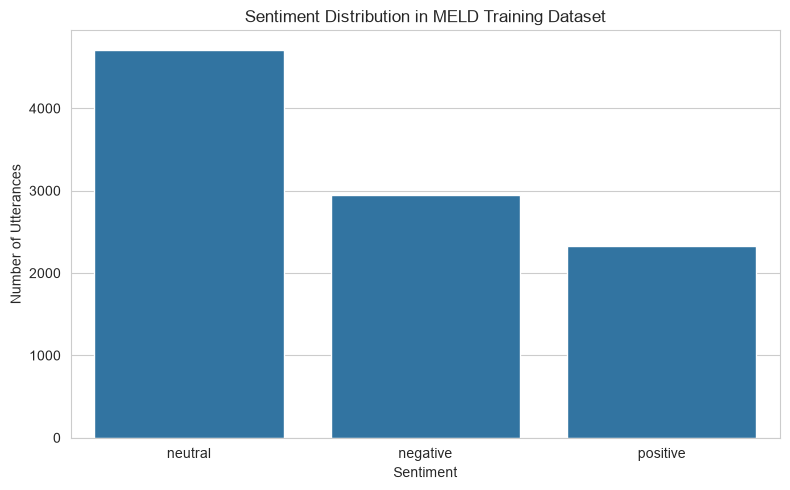

In [13]:
# ==========================================
# 10. SENTIMENT DISTRIBUTION
# ==========================================

sentiment_counts = train_df["Sentiment"].value_counts()

print(sentiment_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Sentiment",
    order=sentiment_counts.index
)

plt.title("Sentiment Distribution in MELD Training Dataset")
plt.xlabel("Sentiment")
plt.ylabel("Number of Utterances")

plt.tight_layout()
plt.show()

Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64


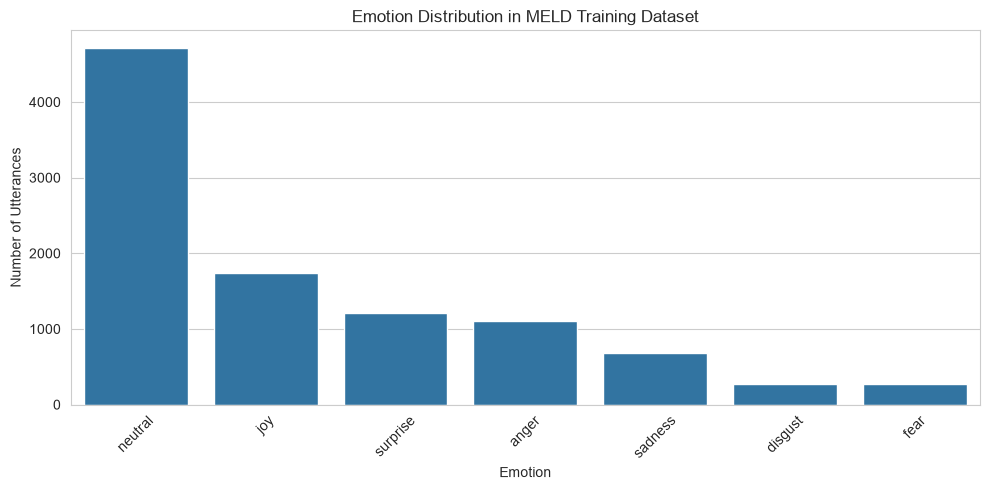

In [14]:
# ==========================================
# 11. EMOTION DISTRIBUTION
# ==========================================

emotion_counts = train_df["Emotion"].value_counts()

print(emotion_counts)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="Emotion",
    order=emotion_counts.index
)

plt.title("Emotion Distribution in MELD Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Utterances")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# 12. SPEAKER ANALYSIS
# ==========================================

print("Number of unique speakers:", train_df["Speaker"].nunique())

print("\nTop 10 speakers by number of utterances:")
print(train_df["Speaker"].value_counts().head(10))

Number of unique speakers: 260

Top 10 speakers by number of utterances:
Speaker
Joey        1510
Ross        1458
Rachel      1435
Phoebe      1321
Monica      1299
Chandler    1283
Janice        58
Carol         46
Emily         43
Tag           41
Name: count, dtype: int64


In [16]:
# ==========================================
# 13. DIALOGUE ANALYSIS
# ==========================================

print("Number of unique dialogues:", train_df["Dialogue_ID"].nunique())

messages_per_dialogue = train_df.groupby("Dialogue_ID").size()

print("\nAverage messages per dialogue:", messages_per_dialogue.mean())
print("Maximum messages per dialogue:", messages_per_dialogue.max())
print("Minimum messages per dialogue:", messages_per_dialogue.min())

Number of unique dialogues: 1038

Average messages per dialogue: 9.623314065510597
Maximum messages per dialogue: 24
Minimum messages per dialogue: 1


count    9989.000000
mean        7.948644
std         6.229899
min         1.000000
25%         3.000000
50%         6.000000
75%        11.000000
max        69.000000
Name: Message_Length, dtype: float64


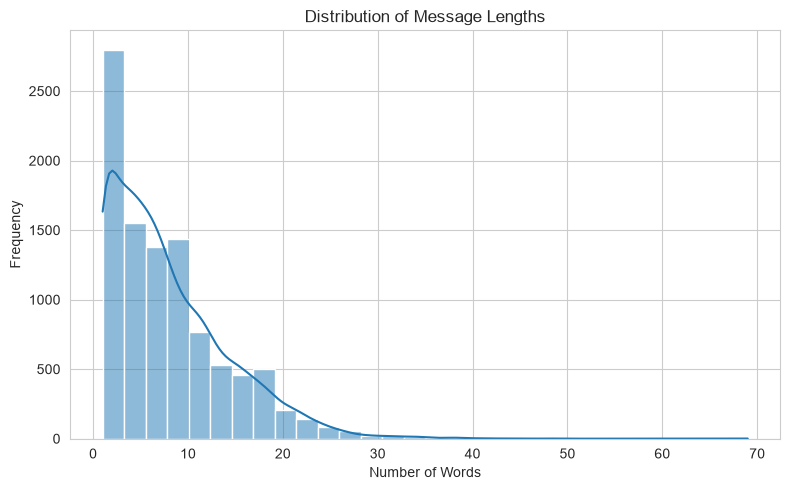

In [17]:
# ==========================================
# 14. MESSAGE LENGTH ANALYSIS
# ==========================================

train_df["Message_Length"] = train_df["Utterance"].astype(str).apply(
    lambda text: len(text.split())
)

print(train_df["Message_Length"].describe())

plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["Message_Length"],
    bins=30,
    kde=True
)

plt.title("Distribution of Message Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
# ==========================================
# 15. SPEAKER-WISE SENTIMENT ANALYSIS
# ==========================================

speaker_sentiment = pd.crosstab(
    train_df["Speaker"],
    train_df["Sentiment"]
)

display(speaker_sentiment.head(10))

Sentiment,negative,neutral,positive
Speaker,,,
1st Customer,0,0,1
2nd Customer,0,0,1
3rd Customer,1,1,0
A Female Student,0,1,0
A Student,1,0,0
Airline Employee,0,2,0
Alice,0,3,0
All,10,11,12
Allesandro,1,3,0
